# **KOMPARASI METODE EXTREME LEARNING MACHINE, SUPPORT VECTOR MACHINE, DAN MULTI-LAYER PERCEPTRON UNTUK PREDIKSI DIABETES**

In [ ]:
!pip install kagglehub -q
!pip install hpelm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 3.3 MB/s eta 0:00:00


In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelBinarizer
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from hpelm import ELM
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
try:
    path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
    print(f"Dataset di-download ke: {path}")
    dataset_dir = path
    csv_file_name = ""
    for file in os.listdir(dataset_dir):
        if file.endswith(".csv"):
            csv_file_name = os.path.join(dataset_dir, file)
            break

    if not csv_file_name:
        raise FileNotFoundError("File CSV dataset tidak ditemukan setelah ekstraksi.")

    print(f"File CSV ditemukan: {csv_file_name}")

except Exception as e:
    print(f"ERROR saat download/ekstrak data: {e}")
    raise

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Dataset di-download ke: /kaggle/input/diabetes-prediction-dataset
File CSV ditemukan: /kaggle/input/diabetes-prediction-dataset/diabetes_prediction_dataset.csv


In [ ]:
#Load dan Processing Data
df = pd.read_csv(csv_file_name)
df_processed = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True)
X = df_processed.drop('diabetes', axis=1)
y = df_processed['diabetes']

print(f"Fitur (X): {X.shape}")
print(f"Target (y): {y.shape}")

Fitur (X): (100000, 13)
Target (y): (100000,)


In [ ]:
#Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    train_size=0.7,
    random_state=42,
    stratify=y
)

In [ ]:
#Scaling Data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#One-Hot Encoding Target untuk ELM
lb = LabelBinarizer()
y_train_ohe = lb.fit_transform(y_train)
y_test_ohe = lb.transform(y_test)
if y_train_ohe.shape[1] == 1:
    y_train_ohe = np.hstack([1 - y_train_ohe, y_train_ohe])
    y_test_ohe = np.hstack([1 - y_test_ohe, y_test_ohe])

print(f"Bentuk Target OHE (untuk ELM): {y_train_ohe.shape}")

Bentuk Target OHE (untuk ELM): (70000, 2)


In [ ]:
#ELM
try:
    hidden_neurons_list = [50, 100, 200]
    activation_functions = ['tanh']

    best_elm_accuracy = 0
    best_elm_config = {}
    y_pred_elm = None
    training_time_elm = 0

    print(f"Memulai Optimasi ELM, menguji {len(hidden_neurons_list) * len(activation_functions)} kombinasi...")
    for n_neurons in hidden_neurons_list:
        for act_func in activation_functions:
            try:
                elm_model = ELM(X_train_scaled.shape[1], y_train_ohe.shape[1])
                elm_model.add_neurons(n_neurons, act_func)

                # 2. Pelatihan
                start_time = time.time()
                elm_model.train(X_train_scaled, y_train_ohe, 'c')
                end_time = time.time()

                # 3. Prediksi
                y_pred_ohe = elm_model.predict(X_test_scaled)
                y_pred_current = np.argmax(y_pred_ohe, axis=1)
                accuracy_current = accuracy_score(y_test, y_pred_current)

                print(f" -> ELM ({n_neurons}N, {act_func}): Akurasi={accuracy_current:.4f}")

                # 4. Simpan yang terbaik
                if accuracy_current > best_elm_accuracy:
                    best_elm_accuracy = accuracy_current
                    best_elm_config = {'Neurons': n_neurons, 'Activation': act_func}
                    y_pred_elm = y_pred_current
                    training_time_elm = end_time - start_time

            except Exception as e:
                print(f"   [SKIP] Error melatih ELM ({n_neurons}N, {act_func}): {e}")
                continue

    if y_pred_elm is not None:
        if 'results' not in globals():
            results = {}
        results['ELM (Optimized)'] = {'Accuracy': best_elm_accuracy, 'Time (s)': training_time_elm}
        cm_elm = confusion_matrix(y_test, y_pred_elm)

    else:
        print(" ELM gagal dilatih.")

except Exception as e:
    print(f"ERROR saat melatih ELM: {e}")

Memulai Optimasi ELM, menguji 3 kombinasi...
 -> ELM (50N, tanh): Akurasi=0.9422
 -> ELM (100N, tanh): Akurasi=0.9440
 -> ELM (200N, tanh): Akurasi=0.9574



--- Hasil Terbaik ELM ---
Konfigurasi Terbaik: {'Neurons': 200, 'Activation': 'tanh'}
Waktu Latih ELM Terbaik: 4.4558 detik
Akurasi ELM Terbaik: 0.9574
Classification Report ELM:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     27450
           1       0.92      0.55      0.69      2550

    accuracy                           0.96     30000
   macro avg       0.94      0.77      0.83     30000
weighted avg       0.96      0.96      0.95     30000



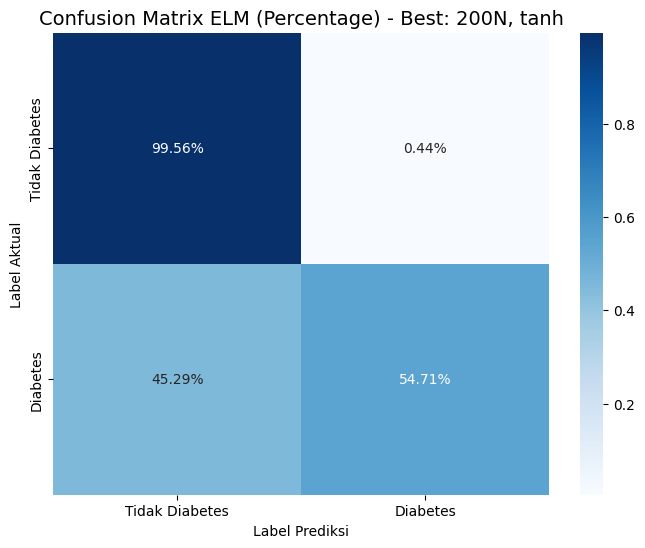

In [ ]:
if y_pred_elm is not None:
    print("\n--- Hasil Terbaik ELM ---")
    print(f"Konfigurasi Terbaik: {best_elm_config}")
    print(f"Waktu Latih ELM Terbaik: {training_time_elm:.4f} detik")
    print(f"Akurasi ELM Terbaik: {best_elm_accuracy:.4f}")
    print("Classification Report ELM:")
    print(classification_report(y_test, y_pred_elm))
    cm_elm_normalized = cm_elm.astype('float') / cm_elm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_elm_normalized, annot=True, fmt='.2%', cmap='Blues',
                xticklabels=['Tidak Diabetes', 'Diabetes'], yticklabels=['Tidak Diabetes', 'Diabetes'])
    plt.title(f'Confusion Matrix ELM (Percentage) - Best: {best_elm_config["Neurons"]}N, {best_elm_config["Activation"]}', fontsize=14)
    plt.xlabel('Label Prediksi')
    plt.ylabel('Label Aktual')
    plt.show()
else:
    print("PERINGATAN: Tidak ada hasil ELM yang tersedia untuk ditampilkan.")

In [ ]:
try:
    svm_model = SVC(kernel='rbf', C=1.0, random_state=42)

    start_time = time.time()
    svm_model.fit(X_train_scaled, y_train)
    end_time = time.time()

    y_pred_svm = svm_model.predict(X_test_scaled)
    training_time_svm = end_time - start_time
    accuracy_svm = accuracy_score(y_test, y_pred_svm)

    results['SVM (RBF)'] = {'Accuracy': accuracy_svm, 'Time (s)': training_time_svm}

    cm_svm = confusion_matrix(y_test, y_pred_svm)
    cm_percent = cm_svm.astype(float) / cm_svm.sum(axis=1)[:, None]

except Exception as e:
    print(f"ERROR saat melatih SVM: {e}")


--- Hasil Terbaik SVM ---
Waktu Latih SVM: 38.4808 detik
Akurasi SVM: 0.9636
Classification Report SVM:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     27450
           1       0.97      0.59      0.73      2550

    accuracy                           0.96     30000
   macro avg       0.97      0.80      0.86     30000
weighted avg       0.96      0.96      0.96     30000



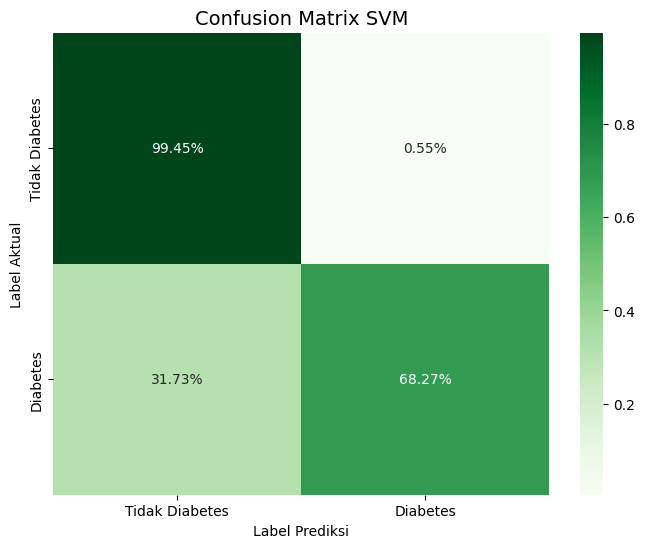

In [ ]:
if 'y_pred_svm' in globals() and y_pred_svm is not None:
    print("\n--- Hasil Terbaik SVM ---")
    print(f"Waktu Latih SVM: {training_time_svm:.4f} detik")
    print(f"Akurasi SVM: {accuracy_svm:.4f}")
    print("Classification Report SVM:")
    print(classification_report(y_test, y_pred_svm))

    # Calculate and Visualize Numerical Confusion Matrix for SVM
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_percent, annot=True, fmt='.2%', cmap='Greens',
                xticklabels=['Tidak Diabetes', 'Diabetes'], yticklabels=['Tidak Diabetes', 'Diabetes'])
    plt.title('Confusion Matrix SVM', fontsize=14)
    plt.xlabel('Label Prediksi')
    plt.ylabel('Label Aktual')
    plt.show()
else:
    print("PERINGATAN: Tidak ada hasil SVM yang tersedia untuk ditampilkan.")

In [ ]:
# MLP
try:
    mlp = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42,
                        activation='relu', solver='adam', early_stopping=True)

    start_time = time.time()
    mlp.fit(X_train_scaled, y_train)
    end_time = time.time()

    y_pred_mlp = mlp.predict(X_test_scaled)
    training_time_mlp = end_time - start_time
    accuracy_mlp = accuracy_score(y_test, y_pred_mlp)

    results['MLP'] = {'Accuracy': accuracy_mlp, 'Time (s)': training_time_mlp}

    cm_mlp = confusion_matrix(y_test, y_pred_mlp)
    cm_percent_mlp = cm_mlp.astype(float) / cm_mlp.sum(axis=1)[:, None]

except Exception as e:
    print(f"ERROR saat melatih MLP: {e}")


--- Hasil Terbaik MLP ---
Waktu Latih MLP: 53.1581 detik
Akurasi MLP: 0.9715
Classification Report MLP:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     27450
           1       0.97      0.69      0.80      2550

    accuracy                           0.97     30000
   macro avg       0.97      0.84      0.89     30000
weighted avg       0.97      0.97      0.97     30000



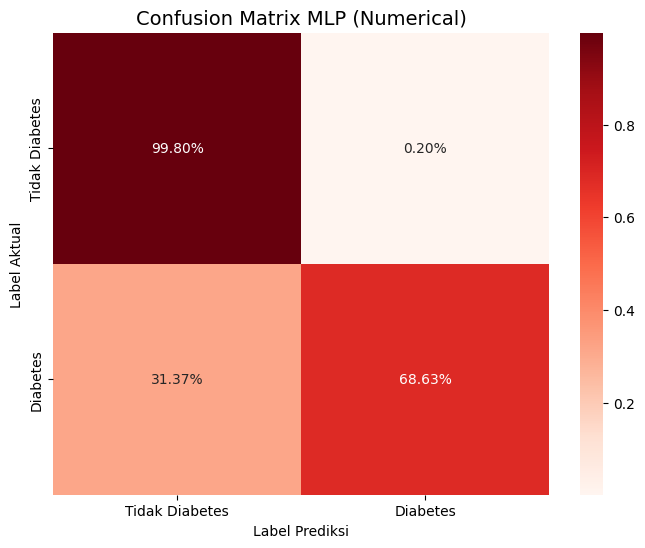

In [ ]:
if 'y_pred_mlp' in globals() and y_pred_mlp is not None:
    print("\n--- Hasil Terbaik MLP ---")
    print(f"Waktu Latih MLP: {training_time_mlp:.4f} detik")
    print(f"Akurasi MLP: {accuracy_mlp:.4f}")
    print("Classification Report MLP:")
    print(classification_report(y_test, y_pred_mlp))

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_percent_mlp, annot=True, fmt='.2%', cmap='Reds',
                xticklabels=['Tidak Diabetes', 'Diabetes'], yticklabels=['Tidak Diabetes', 'Diabetes'])
    plt.title('Confusion Matrix MLP (Numerical)', fontsize=14)
    plt.xlabel('Label Prediksi')
    plt.ylabel('Label Aktual')
    plt.show()
else:
    print("PERINGATAN: Tidak ada hasil MLP yang tersedia untuk ditampilkan.")



Perbandingan Hasil Akhir Model
--- Tabel Perbandingan Kinerja ---
                 Accuracy   Time (s)
MLP              0.971533  29.571080
SVM (RBF)        0.963600  48.055110
ELM (Optimized)  0.957433   4.455824

Analisis Singkat:
Model terbaik berdasarkan akurasi adalah *MLP* dengan akurasi *0.9715*.
Perhatikan ELM (Fast JST) vs. MLP (Iterative JST) dan SVM (ML Klasik) dari segi Akurasi dan Waktu Latih.


/tmp/ipython-input-2921165930.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_results.index,


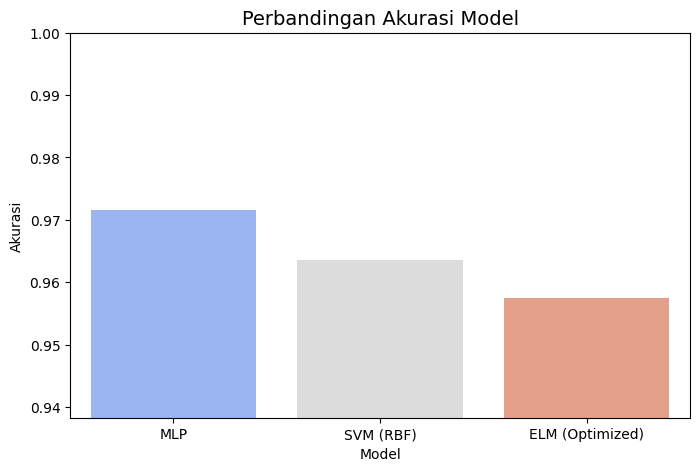

/tmp/ipython-input-2921165930.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_results_time.index,


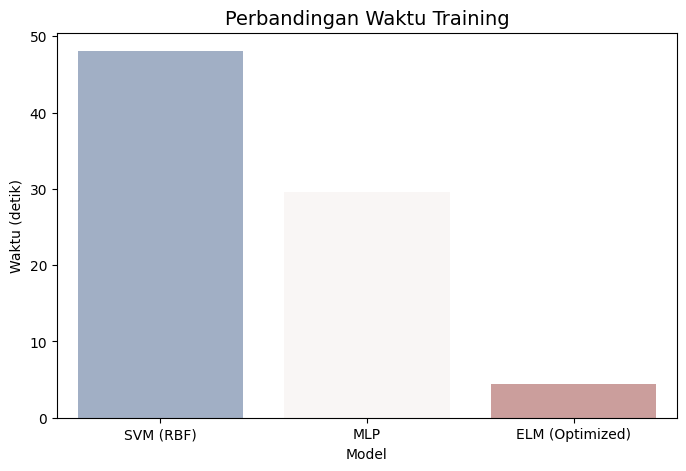

In [ ]:
#Komparasi Model
print("\n\n" + "="*60)
print("Perbandingan Hasil Akhir Model")
print("="*60)

if results:
    df_results = pd.DataFrame(results).T
    df_results = df_results.sort_values(by='Accuracy', ascending=False)

    print("--- Tabel Perbandingan Kinerja ---")
    print(df_results)

    print("\nAnalisis Singkat:")
    print(f"Model terbaik berdasarkan akurasi adalah *{df_results.index[0]}* dengan akurasi *{df_results.iloc[0, 0]:.4f}*.")
    print("Perhatikan ELM (Fast JST) vs. MLP (Iterative JST) dan SVM (ML Klasik) dari segi Akurasi dan Waktu Latih.")

    plt.figure(figsize=(8, 5))
    sns.barplot(x=df_results.index,
                y=df_results['Accuracy'],
                palette='coolwarm')
    plt.title('Perbandingan Akurasi Model', fontsize=14)
    plt.xlabel('Model')
    plt.ylabel('Akurasi')
    plt.ylim(df_results['Accuracy'].min() * 0.98, 1.0)
    plt.show()
    df_results_time = df_results.sort_values(by='Time (s)', ascending=False)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=df_results_time.index,
                y=df_results_time['Time (s)'],
                palette='vlag')
    plt.title('Perbandingan Waktu Training', fontsize=14)
    plt.xlabel('Model')
    plt.ylabel('Waktu (detik)')
    plt.show()

else:
    print("Tidak ada model yang berhasil dilatih. Tidak ada hasil untuk ditampilkan.")

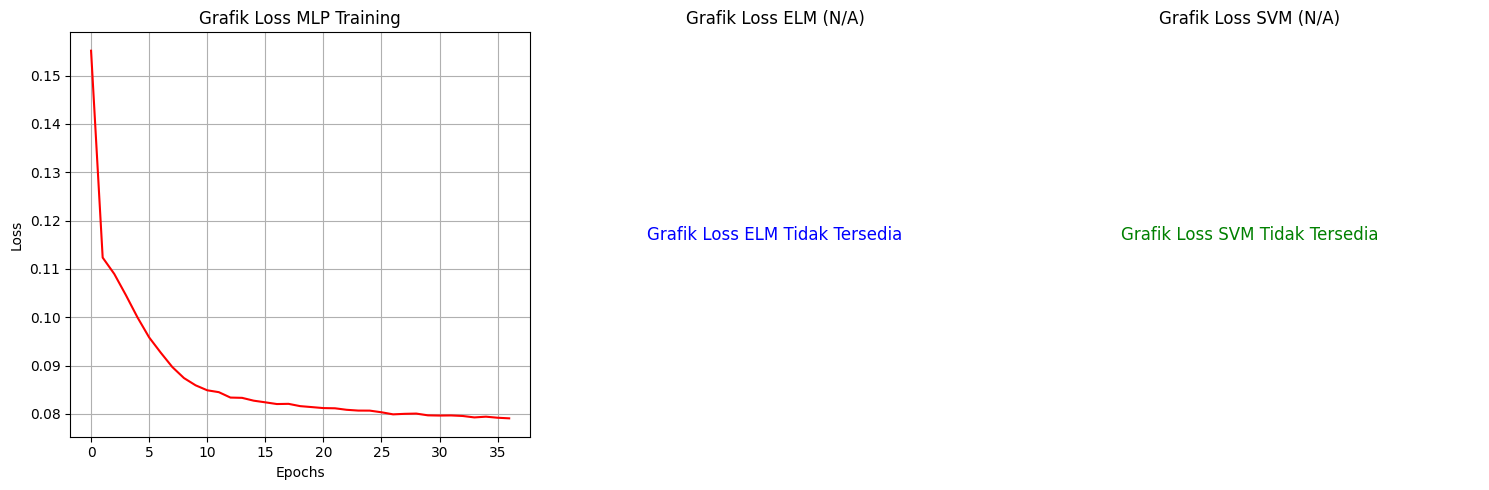

In [ ]:
plt.figure(figsize=(15, 5))

# --- MLP Loss  ---
if 'mlp' in globals() and mlp is not None and hasattr(mlp, 'loss_curve_'):
    plt.subplot(1, 3, 1)
    plt.plot(mlp.loss_curve_, label='MLP Loss', color='red')
    plt.title('Grafik Loss MLP Training')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True)
else:
    plt.subplot(1, 3, 1)
    plt.text(0.5, 0.5, 'MLP Loss Not Available', horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes, fontsize=12, color='red')
    plt.title('Grafik Loss MLP (Tidak Ditemukan)')
    plt.axis('off')

# --- ELM Loss ---
plt.subplot(1, 3, 2)
plt.text(0.5, 0.5, 'Grafik Loss ELM Tidak Tersedia', horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes, fontsize=12, color='blue')
plt.title('Grafik Loss ELM (N/A)')
plt.axis('off')

# --- SVM Loss  ---
plt.subplot(1, 3, 3)
plt.text(0.5, 0.5, 'Grafik Loss SVM Tidak Tersedia', horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes, fontsize=12, color='green')
plt.title('Grafik Loss SVM (N/A)')
plt.axis('off')

plt.tight_layout()
plt.show()
